# 💰 Módulo 3 — Otimização Prescritiva do Cupom Ideal, Incerteza e Política Segmentada

**Autor:** Dr. Silvio da Rosa Paula — Doutor em Economia Aplicada & Cientista de Dados

---

## 1. Função de Lucro Líquido em U Invertido $\Pi(d)$ e Fronteira de *Breakeven*

Acoplando as curvas causais estimadas $\hat L_k(d)$ à margem unitária de cada categoria, o lucro líquido esperado na Black Friday em função do percentual de cupom $d \in [0\%, 35\%]$ é:
$$\Pi(d) = \sum_{k} Q_{0,k} \cdot \big(1 + \hat L_k(d)\big) \cdot \big[P_k (m_{0,k} - d) - c_{v,k}\big]$$

Como $\hat L_k(d)$ possui **retornos marginais decrescentes** ($\hat L_k''(d) < 0$) enquanto cada ponto percentual adicional de cupom corrói linearmente a margem unitária de **todos** os pedidos (inclusive dos clientes orgânicos $Q_{0,k}$!), $\Pi(d)$ descreve uma **curva em U invertido** com máximo interior único $d^*$:
- Abaixo de $d^*$: o ganho de volume supera a cessão de margem.
- Acima de $d^*$: a canibalização de margem supera o volume incremental, entrando em **destruição severa de valor acima de `25%–30%`**.

Cupom Único Ótimo (Neutro ao Risco) : d* = 12.0%
Cupom Único Ótimo (Averso ao Risco) : d* = 12.0% (max E[Π] - 1,5·DP)


,cupom_pct,margem_unit_rs,lift_est_pct,lift_true_pct,lift_breakeven_vs_0_pct,lucro_est_rs,lucro_true_rs,lucro_p10_rs,lucro_p90_rs,lucro_sd_rs,utilidade_aversao_risco_rs
0,0.0,230.00,0.00,0.00,0.00,4222982.14,4222982.14,4222982.15,4222982.15,0.00,4222982.14
15,7.5,203.75,30.29,30.31,12.88,4798327.32,4797608.27,4787040.95,4808691.31,8082.78,4786203.15
20,10.0,195.00,38.43,38.48,17.95,4861572.47,4861721.17,4851094.03,4870819.81,7618.90,4850144.12
24,12.0,188.00,44.36,44.43,22.34,4875135.04,4876148.02,4865692.04,4883339.36,6890.26,4864799.65
30,15.0,177.50,52.36,52.48,29.58,4841576.66,4844014.61,4833028.92,4848805.76,6049.19,4832502.88
40,20.0,160.00,63.66,63.86,43.75,4665427.96,4670203.32,4655309.39,4675142.74,7470.56,4654222.12
50,25.0,142.50,72.84,73.14,61.40,4370309.26,4376997.21,4355529.21,4384613.27,11002.86,4353804.97
60,30.0,125.00,80.32,80.70,84.00,3984609.00,3992574.34,3965915.36,4003311.72,14203.59,3963303.61
70,35.0,107.50,86.41,86.86,113.95,3530012.02,3538563.57,3508526.49,3551551.22,16217.50,3505685.77


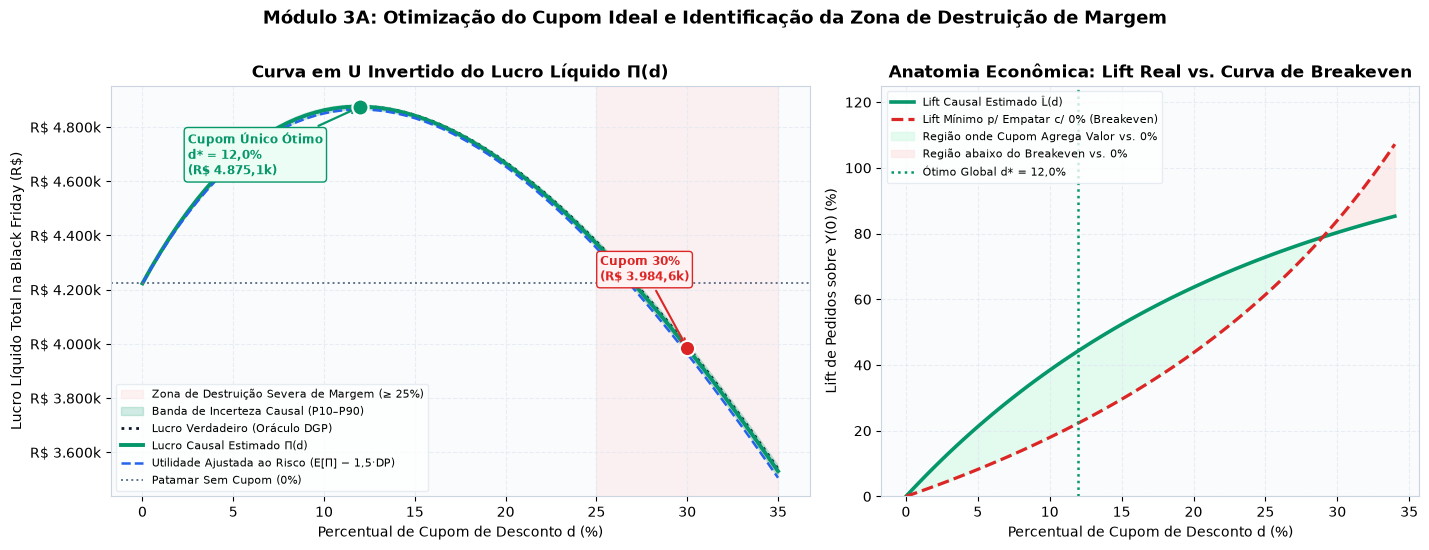

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display

from src.dgp import save_or_load_panel
from src.causal_models import fit_did_and_dose_response
from src.optimizer import evaluate_coupon_grid
from src.visuals import plot_05_inverted_u_profit_curve, plot_06_segmented_policy_comparison

PROJ_ROOT = Path(".").resolve()
df = save_or_load_panel(PROJ_ROOT / "data", seed=2025)
did_res = fit_did_and_dose_response(df, seed=42)
opt_res = evaluate_coupon_grid(df, did_res["fitted_curves"], risk_aversion_lambda=1.5)

print(f"Cupom Único Ótimo (Neutro ao Risco) : d* = {opt_res['d_star_single_pct']:.1f}%")
print(f"Cupom Único Ótimo (Averso ao Risco) : d* = {opt_res['d_star_risk_averse_pct']:.1f}% (max E[Π] - 1,5·DP)")

gc = opt_res["global_curve_df"]
display(gc[gc["cupom_pct"].isin([0.0, 7.5, 10.0, 12.0, 15.0, 20.0, 25.0, 30.0, 35.0])])

fig5 = plot_05_inverted_u_profit_curve(opt_res, save_path=PROJ_ROOT / "img" / "05_curva_lucro_u_invertido.png")
plt.show()

---
## 2. Política Segmentada por Categoria ($d^*_{\text{Móveis}} \neq d^*_{\text{Têxtil}}$) e Impacto Financeiro Final

Em vez de aplicar o mesmo cupom de `12,0%` para toda a loja, usamos as curvas heterogêneas do Módulo 2C para otimizar separadamente cada linha de produto e comparamos o **lucro líquido real** na janela da Black Friday (toda a rede, 16 unidades × 10 dias) entre 5 políticas!

Categoria Móveis & Iluminação    -> Cupom Ótimo d*_k =  7.5% | Lift em d*_k = +18.70% | Lucro Realizado = R$ 2,374,812.18
Categoria Têxtil & Objetos       -> Cupom Ótimo d*_k = 15.0% | Lift em d*_k = +68.79% | Lucro Realizado = R$ 2,549,123.64

=== COMPARATIVO EXECUTIVO DE POLÍTICAS NA BLACK FRIDAY (TODA A REDE) ===


,Politica,Regra_Desconto,Lucro_Liquido_Real_RS,Ganho_vs_30pct_RS,Ganho_vs_20pct_RS
0,1. Cupom 30% (Decisão Ingênua +40%),"30,0% uniforme",3992574.34,0.00,-677628.98
1,2. Sem Cupom (0% — Margem Cheia),"0,0% uniforme",4222982.14,230407.80,-447221.18
2,3. Cupom 20% (Status Quo Histórico),"20,0% uniforme",4670203.32,677628.98,0.00
3,"4. Cupom Único Ótimo Causal (d* = 12,0%)","12,0% uniforme",4876148.02,883573.68,205944.70
4,5. Política Segmentada Causal (CATE),"Móveis 7,5% | Têxtil 15,0%",4923935.82,931361.48,253732.50


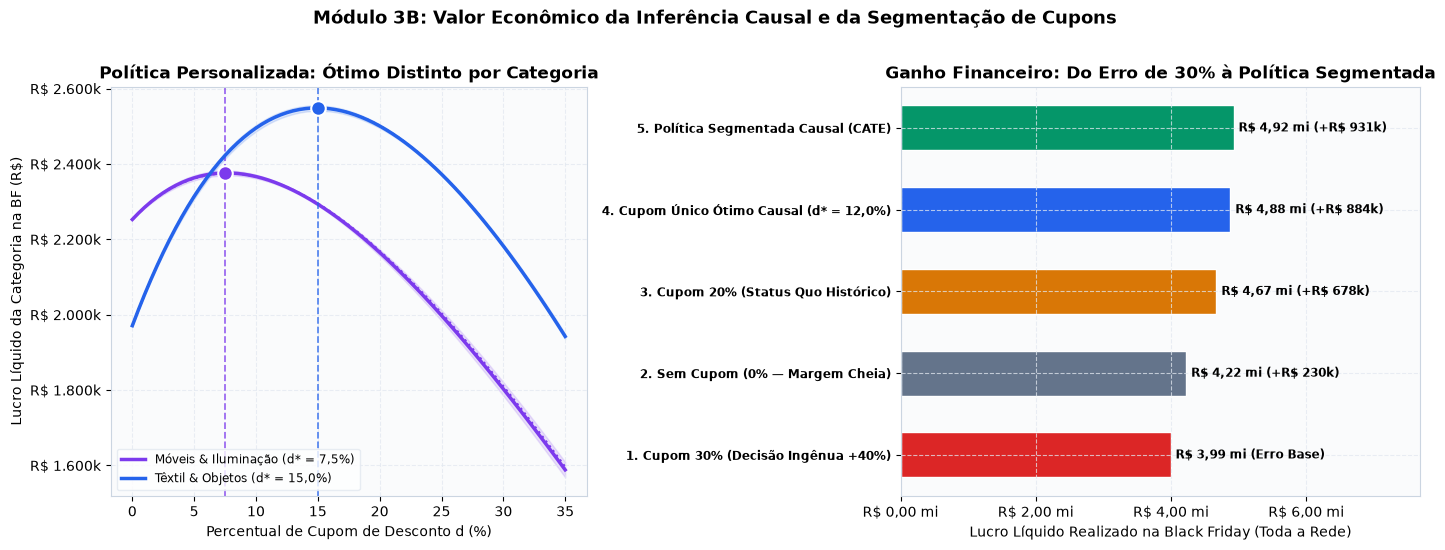

In [2]:
for k, info in opt_res["opt_by_cat"].items():
    print(f"Categoria {info['label']:22s} -> Cupom Ótimo d*_k = {info['d_star_pct']:4.1f}% | Lift em d*_k = +{info['lift_est_at_dstar_pct']:5.2f}% | Lucro Realizado = R$ {info['profit_true_realized_rs']:,.2f}")

print("\n=== COMPARATIVO EXECUTIVO DE POLÍTICAS NA BLACK FRIDAY (TODA A REDE) ===")
display(opt_res["policy_comparison_df"])

fig6 = plot_06_segmented_policy_comparison(opt_res, save_path=PROJ_ROOT / "img" / "06_politica_segmentada_risco.png")
plt.show()

### Síntese Prescritiva para a Diretoria
1. **Evitar a armadilha do cupom de `30%` preserva imediatamente +R\$ 677,6 mil** mesmo apenas mantendo o status quo histórico de `20%`.
2. **Recalibrar o cupom único da loja de `20%` para o ponto ótimo causal `d* = 12,0%`** adiciona mais **+R\$ 205,9 mil** de margem líquida (**+R\$ 883,6 mil** contra o erro de `30%`), com estabilidade total mesmo sob cenários pessimistas (`P10`) e aversão ao risco.
3. **Adotar a Política Segmentada Causal (`7,5%` em *Móveis & Iluminação* e `15,0%` em *Têxtil & Objetos*)** captura a heterogeneidade de elasticidade-preço e eleva o lucro líquido total para **R\$ 4,92 milhões**, gerando **+R\$ 931,4 mil** acima da política ingênua de `30%` e **+R\$ 253,7 mil** acima do cupom uniforme de `20%`!